In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import pprint
import sys

# Data transformers
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, label_binarize, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

np.set_printoptions(suppress=True, linewidth=200, threshold=1000000, precision=3, edgeitems=1000 )


In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
path='/content/drive/MyDrive/Science_Fair_Data_2025-2026/ConsolidatedCSV9.csv'

In [4]:
df=pd.read_csv(path)
df

,Substance,Laser_Intenstity,194.1151,196.1586,198.2017,200.2442,202.2863,204.3278,206.3688,208.4094,...,3357.1519,3358.3602,3359.5684,3360.7764,3361.9843,3363.1921,3364.3998,3365.6074,3366.8148,3368.0221
0,No T4,0.35,204.7,204.7,204.7,204.7,204.7,204.7,204.7,204.7,...,7.8,4.9,3.1,-8.5,5.0,4.4,6.2,5.2,5.2,5.2
1,No T4,0.40,404.4,404.4,404.4,404.4,404.4,404.4,404.4,404.4,...,9.9,-0.5,3.1,0.8,4.2,3.8,2.9,6.0,6.0,6.0
2,No T4,0.45,607.3,607.3,607.3,607.3,607.3,607.3,607.3,607.3,...,15.6,13.8,9.9,10.2,18.2,15.3,17.0,6.2,6.2,6.2
3,No T4,0.50,866.9,866.9,866.9,866.9,866.9,866.9,866.9,866.9,...,17.7,18.7,20.2,21.8,24.7,23.7,19.4,14.3,14.3,14.3
4,No T4,0.55,1122.4,1122.4,1122.4,1122.4,1122.4,1122.4,1122.4,1122.4,...,25.8,26.6,29.8,24.4,28.7,26.6,26.7,30.9,30.9,30.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,T4 Present,0.55,994.9,994.9,994.9,994.9,994.9,994.9,994.9,994.9,...,24.9,17.9,14.2,9.4,17.5,28.9,21.4,11.1,11.1,11.1
74,T4 Present,0.60,1208.0,1208.0,1208.0,1208.0,1208.0,1208.0,1208.0,1208.0,...,28.2,26.6,28.2,27.6,29.9,23.8,27.5,31.3,31.3,31.3
75,T4 Present,0.65,1395.7,1395.7,1395.7,1395.7,1395.7,1395.7,1395.7,1395.7,...,22.1,23.2,29.5,28.4,26.0,25.5,22.4,16.1,16.1,16.1
76,T4 Present,0.70,1579.4,1579.4,1579.4,1579.4,1579.4,1579.4,1579.4,1579.4,...,37.4,39.2,45.7,42.1,36.5,40.5,39.9,34.9,34.9,34.9


In [5]:
num_col = ['Laser_Intenstity','194.1151','196.1586','198.2017','200.2442','202.2863','204.3278','206.3688','208.4094','210.4494','212.4889','214.528','216.5665','218.6045','220.6421','222.6791','224.7156','226.7517','228.7872','230.8222','232.8567','234.8907','236.9242','238.9572','240.9897','243.0217','245.0532','247.0842','249.1147','251.1446','253.1741','255.2031','257.2315','259.2594','261.2869','263.3138','265.3402','267.3661','269.3915','271.4164','273.4408','275.4647','277.488','279.5109','281.5332','283.555','285.5764','287.5972','289.6175','291.6372','293.6565','295.6753','297.6935','299.7112','301.7285','303.7452','305.7614','307.777','309.7922','311.8069','313.821','315.8346','317.8477','319.8603','321.8724','323.8839','325.895','327.9055','329.9155','331.925','333.934','335.9424','337.9504','339.9578','341.9647','343.9711','345.9769','347.9823','349.9871','351.9914','353.9952','355.9985','358.0012','360.0034','362.0051','364.0063','366.007','368.0071','370.0067','372.0058','374.0044','376.0025','378','379.997','381.9935','383.9895','385.9849','387.9798','389.9742','391.9681','393.9614','395.9542','397.9465','399.9383','401.9295','403.9203','405.9104','407.9001','409.8893','411.8779','413.866','415.8535','417.8406','419.8271','421.813','423.7985','425.7834','427.7678','429.7517','431.735','433.7178','435.7001','437.6819','439.6631','441.6438','443.624','445.6036','447.5827','449.5613','451.5394','453.5169','455.4939','457.4703','459.4462','461.4216','463.3965','465.3708','467.3446','469.3179','471.2906','473.2628','475.2345','477.2056','479.1763','481.1463','483.1159','485.0849','487.0533','489.0213','490.9887','492.9556','494.9219','496.8877','498.853','500.8177','502.7819','504.7456','506.7087','508.6713','510.6334','512.5949','514.5559','516.5163','518.4762','520.4356','522.3944','524.3528','526.3105','528.2678','530.2245','532.1806','534.1362','536.0913','538.0459','539.9999','541.9533','543.9063','545.8587','547.8105','549.7618','551.7126','553.6628','555.6125','557.5617','559.5103','561.4584','563.4059','565.3529','567.2994','569.2453','571.1907','573.1356','575.0799','577.0236','578.9668','580.9095','582.8517','584.7933','586.7343','588.6748','590.6148','592.5542','594.4931','596.4315','598.3693','600.3065','602.2433','604.1794','606.1151','608.0502','609.9847','611.9187','613.8522','615.7851','617.7175','619.6494','621.5807','623.5114','625.4416','627.3713','629.3004','631.229','633.157','635.0845','637.0114','638.9378','640.8637','642.789','644.7138','646.638','648.5617','650.4848','652.4074','654.3294','656.2509','658.1719','660.0923','662.0121','663.9314','665.8502','667.7684','669.6861','671.6032','673.5198','675.4359','677.3513','679.2663','681.1807','683.0945','685.0078','686.9206','688.8328','690.7445','692.6556','694.5662','696.4762','698.3857','700.2946','702.203','704.1108','706.0181','707.9248','709.831','711.7367','713.6418','715.5463','717.4503','719.3538','721.2567','723.159','725.0608','726.9621','728.8628','730.7629','732.6626','734.5616','736.4601','738.3581','740.2555','742.1524','744.0487','745.9445','747.8397','749.7344','751.6285','753.522','755.4151','757.3075','759.1995','761.0908','762.9817','764.8719','766.7617','768.6508','770.5395','772.4275','774.3151','776.202','778.0885','779.9743','781.8597','783.7444','785.6287','787.5123','789.3955','791.278','793.1601','795.0415','796.9225','798.8028','800.6827','802.5619','804.4406','806.3188','808.1964','810.0735','811.95','813.826','815.7014','817.5763','819.4506','821.3243','823.1975','825.0702','826.9423','828.8139','830.6849','832.5553','834.4252','836.2946','838.1634','840.0316','841.8993','843.7665','845.6331','847.4991','849.3646','851.2296','853.094','854.9578','856.8211','858.6838','860.546','862.4076','864.2687','866.1292','867.9892','869.8486','871.7075','873.5658','875.4236','877.2808','879.1375','880.9936','882.8492','884.7042','886.5586','888.4125','890.2659','892.1187','893.9709','895.8226','897.6738','899.5244','901.3744','903.2239','905.0729','906.9213','908.7691','910.6164','912.4631','914.3093','916.1549','918','919.8445','921.6885','923.5319','925.3748','927.2171','929.0589','930.9001','932.7407','934.5809','936.4204','938.2594','940.0979','941.9358','943.7731','945.6099','947.4462','949.2819','951.117','952.9516','954.7857','956.6191','958.4521','960.2845','962.1163','963.9476','965.7783','967.6085','969.4381','971.2672','973.0957','974.9237','976.7511','978.578','980.4043','982.2301','984.0553','985.8799','987.704','989.5276','991.3506','993.1731','994.995','996.8163','998.6371','1000.4574','1002.2771','1004.0962','1005.9148','1007.7329','1009.5504','1011.3673','1013.1837','1014.9996','1016.8149','1018.6296','1020.4438','1022.2574','1024.0705','1025.8831','1027.695','1029.5065','1031.3174','1033.1277','1034.9375','1036.7467','1038.5554','1040.3635','1042.1711','1043.9782','1045.7846','1047.5906','1049.396','1051.2008','1053.0051','1054.8088','1056.612','1058.4146','1060.2167','1062.0182','1063.8192','1065.6196','1067.4195','1069.2189','1071.0176','1072.8159','1074.6136','1076.4107','1078.2073','1080.0033','1081.7988','1083.5937','1085.3881','1087.182','1088.9752','1090.768','1092.5602','1094.3518','1096.1429','1097.9335','1099.7235','1101.5129','1103.3018','1105.0901','1106.878','1108.6652','1110.4519','1112.2381','1114.0237','1115.8087','1117.5932','1119.3772','1121.1606','1122.9435','1124.7258','1126.5076','1128.2888','1130.0695','1131.8496','1133.6292','1135.4082','1137.1867','1138.9647','1140.742','1142.5189','1144.2952','1146.0709','1147.8461','1149.6208','1151.3949','1153.1685','1154.9415','1156.714','1158.4859','1160.2573','1162.0281','1163.7984','1165.5681','1167.3373','1169.106','1170.8741','1172.6416','1174.4086','1176.1751','1177.941','1179.7064','1181.4712','1183.2355','1184.9992','1186.7624','1188.5251','1190.2872','1192.0487','1193.8097','1195.5702','1197.3301','1199.0895','1200.8483','1202.6066','1204.3644','1206.1216','1207.8782','1209.6343','1211.3899','1213.1449','1214.8994','1216.6534','1218.4068','1220.1596','1221.9119','1223.6637','1225.4149','1227.1656','1228.9157','1230.6653','1232.4144','1234.1629','1235.9108','1237.6582','1239.4051','1241.1515','1242.8973','1244.6425','1246.3872','1248.1314','1249.875','1251.6181','1253.3607','1255.1027','1256.8441','1258.585','1260.3254','1262.0653','1263.8046','1265.5433','1267.2815','1269.0192','1270.7563','1272.4929','1274.229','1275.9645','1277.6995','1279.4339','1281.1678','1282.9012','1284.634','1286.3663','1288.098','1289.8292','1291.5599','1293.29','1295.0196','1296.7486','1298.4771','1300.2051','1301.9325','1303.6594','1305.3858','1307.1116','1308.8368','1310.5616','1312.2858','1314.0094','1315.7326','1317.4552','1319.1772','1320.8987','1322.6197','1324.3401','1326.0601','1327.7794','1329.4982','1331.2165','1332.9343','1334.6515','1336.3682','1338.0844','1339.8','1341.5151','1343.2296','1344.9436','1346.6571','1348.37','1350.0824','1351.7943','1353.5056','1355.2164','1356.9267','1358.6364','1360.3456','1362.0543','1363.7624','1365.47','1367.1771','1368.8836','1370.5896','1372.2951','1374','1375.7044','1377.4083','1379.1116','1380.8144','1382.5167','1384.2184','1385.9196','1387.6203','1389.3204','1391.02','1392.7191','1394.4176','1396.1157','1397.8131','1399.5101','1401.2065','1402.9024','1404.5978','1406.2926','1407.9869','1409.6807','1411.3739','1413.0666','1414.7588','1416.4504','1418.1416','1419.8322','1421.5222','1423.2118','1424.9008','1426.5892','1428.2772','1429.9646','1431.6515','1433.3379','1435.0237','1436.709','1438.3938','1440.0781','1441.7618','1443.445','1445.1277','1446.8098','1448.4914','1450.1725','1451.8531','1453.5331','1455.2127','1456.8917','1458.5701','1460.2481','1461.9255','1463.6024','1465.2787','1466.9546','1468.6299','1470.3047','1471.9789','1473.6527','1475.3259','1476.9986','1478.6708','1480.3424','1482.0135','1483.6841','1485.3542','1487.0238','1488.6928','1490.3613','1492.0293','1493.6968','1495.3637','1497.0301','1498.696','1500.3614','1502.0263','1503.6906','1505.3544','1507.0177','1508.6805','1510.3427','1512.0045','1513.6657','1515.3264','1516.9866','1518.6462','1520.3053','1521.964','1523.622','1525.2796','1526.9367','1528.5932','1530.2492','1531.9047','1533.5597','1535.2142','1536.8681','1538.5216','1540.1745','1541.8269','1543.4788','1545.1301','1546.781','1548.4313','1550.0811','1551.7304','1553.3792','1555.0274','1556.6752','1558.3224','1559.9692','1561.6154','1563.261','1564.9062','1566.5509','1568.195','1569.8387','1571.4818','1573.1244','1574.7665','1576.408','1578.0491','1579.6896','1581.3297','1582.9692','1584.6082','1586.2467','1587.8847','1589.5222','1591.1591','1592.7956','1594.4315','1596.067','1597.7019','1599.3363','1600.9702','1602.6036','1604.2365','1605.8688','1607.5007','1609.132','1610.7629','1612.3932','1614.023','1615.6523','1617.2811','1618.9094','1620.5372','1622.1645','1623.7912','1625.4175','1627.0433','1628.6685','1630.2932','1631.9175','1633.5412','1635.1644','1636.7871','1638.4093','1640.031','1641.6522','1643.2729','1644.8931','1646.5128','1648.1319','1649.7506','1651.3688','1652.9864','1654.6036','1656.2202','1657.8364','1659.452','1661.0672','1662.6818','1664.2959','1665.9096','1667.5227','1669.1353','1670.7475','1672.3591','1673.9702','1675.5808','1677.1909','1678.8005','1680.4097','1682.0183','1683.6264','1685.234','1686.8411','1688.4477','1690.0538','1691.6595','1693.2646','1694.8692','1696.4733','1698.0769','1699.68','1701.2827','1702.8848','1704.4864','1706.0876','1707.6882','1709.2883','1710.888','1712.4871','1714.0857','1715.6839','1717.2815','1718.8787','1720.4754','1722.0715','1723.6672','1725.2624','1726.857','1728.4512','1730.0449','1731.6381','1733.2308','1734.823','1736.4147','1738.006','1739.5967','1741.1869','1742.7767','1744.3659','1745.9547','1747.5429','1749.1307','1750.718','1752.3048','1753.8911','1755.4769','1757.0622','1758.647','1760.2314','1761.8152','1763.3986','1764.9814','1766.5638','1768.1457','1769.7271','1771.308','1772.8884','1774.4684','1776.0478','1777.6268','1779.2053','1780.7832','1782.3607','1783.9377','1785.5143','1787.0903','1788.6659','1790.2409','1791.8155','1793.3896','1794.9632','1796.5363','1798.109','1799.6811','1801.2528','1802.824','1804.3947','1805.9649','1807.5346','1809.1039','1810.6726','1812.2409','1813.8087','1815.376','1816.9429','1818.5092','1820.0751','1821.6405','1823.2054','1824.7698','1826.3338','1827.8972','1829.4602','1831.0227','1832.5848','1834.1463','1835.7074','1837.268','1838.8281','1840.3877','1841.9469','1843.5055','1845.0637','1846.6215','1848.1787','1849.7355','1851.2917','1852.8476','1854.4029','1855.9577','1857.5121','1859.066','1860.6195','1862.1724','1863.7249','1865.2769','1866.8284','1868.3795','1869.9301','1871.4802','1873.0298','1874.579','1876.1277','1877.6759','1879.2236','1880.7709','1882.3177','1883.864','1885.4099','1886.9552','1888.5002','1890.0446','1891.5886','1893.1321','1894.6751','1896.2176','1897.7597','1899.3014','1900.8425','1902.3832','1903.9234','1905.4631','1907.0024','1908.5412','1910.0796','1911.6174','1913.1548','1914.6918','1916.2282','1917.7642','1919.2998','1920.8348','1922.3694','1923.9036','1925.4373','1926.9705','1928.5032','1930.0355','1931.5673','1933.0986','1934.6295','1936.16','1937.6899','1939.2194','1940.7484','1942.277','1943.8051','1945.3328','1946.86','1948.3867','1949.9129','1951.4387','1952.9641','1954.489','1956.0134','1957.5373','1959.0608','1960.5839','1962.1064','1963.6286','1965.1502','1966.6714','1968.1922','1969.7125','1971.2323','1972.7517','1974.2706','1975.789','1977.307','1978.8246','1980.3416','1981.8583','1983.3745','1984.8902','1986.4054','1987.9202','1989.4346','1990.9485','1992.4619','1993.9749','1995.4875','1996.9996','1998.5112','2000.0224','2001.5331','2003.0434','2004.5532','2006.0625','2007.5715','2009.0799','2010.5879','2012.0955','2013.6026','2015.1093','2016.6155','2018.1213','2019.6266','2021.1314','2022.6358','2024.1398','2025.6433','2027.1464','2028.649','2030.1512','2031.6529','2033.1542','2034.655','2036.1554','2037.6554','2039.1548','2040.6539','2042.1525','2043.6507','2045.1484','2046.6456','2048.1424','2049.6388','2051.1348','2052.6302','2054.1253','2055.6199','2057.1141','2058.6078','2060.101','2061.5939','2063.0863','2064.5782','2066.0697','2067.5608','2069.0514','2070.5416','2072.0313','2073.5207','2075.0095','2076.4979','2077.9859','2079.4735','2080.9606','2082.4473','2083.9335','2085.4193','2086.9046','2088.3896','2089.874','2091.3581','2092.8417','2094.3249','2095.8076','2097.2899','2098.7718','2100.2532','2101.7342','2103.2148','2104.6949','2106.1746','2107.6539','2109.1327','2110.6111','2112.089','2113.5666','2115.0437','2116.5203','2117.9966','2119.4724','2120.9477','2122.4227','2123.8972','2125.3712','2126.8449','2128.3181','2129.7909','2131.2633','2132.7352','2134.2067','2135.6778','2137.1484','2138.6186','2140.0884','2141.5578','2143.0267','2144.4952','2145.9633','2147.4309','2148.8982','2150.365','2151.8313','2153.2973','2154.7628','2156.2279','2157.6926','2159.1568','2160.6207','2162.0841','2163.5471','2165.0096','2166.4718','2167.9335','2169.3948','2170.8556','2172.3161','2173.7761','2175.2357','2176.6949','2178.1537','2179.612','2181.0699','2182.5275','2183.9845','2185.4412','2186.8975','2188.3533','2189.8087','2191.2637','2192.7183','2194.1724','2195.6262','2197.0795','2198.5324','2199.9849','2201.437','2202.8887','2204.3399','2205.7907','2207.2412','2208.6912','2210.1407','2211.5899','2213.0387','2214.487','2215.935','2217.3825','2218.8296','2220.2763','2221.7226','2223.1685','2224.6139','2226.059','2227.5036','2228.9479','2230.3917','2231.8351','2233.2781','2234.7207','2236.1629','2237.6047','2239.046','2240.487','2241.9275','2243.3677','2244.8074','2246.2467','2247.6857','2249.1242','2250.5623','2252','2253.4373','2254.8742','2256.3107','2257.7468','2259.1825','2260.6177','2262.0526','2263.4871','2264.9211','2266.3548','2267.7881','2269.2209','2270.6534','2272.0854','2273.5171','2274.9483','2276.3792','2277.8096','2279.2397','2280.6694','2282.0986','2283.5275','2284.9559','2286.384','2287.8116','2289.2389','2290.6657','2292.0922','2293.5183','2294.9439','2296.3692','2297.7941','2299.2186','2300.6427','2302.0663','2303.4896','2304.9125','2306.335','2307.7571','2309.1789','2310.6002','2312.0211','2313.4417','2314.8618','2316.2815','2317.7009','2319.1199','2320.5384','2321.9566','2323.3744','2324.7918','2326.2088','2327.6255','2329.0417','2330.4575','2331.873','2333.288','2334.7027','2336.117','2337.5309','2338.9444','2340.3575','2341.7703','2343.1826','2344.5946','2346.0062','2347.4174','2348.8282','2350.2386','2351.6486','2353.0583','2354.4675','2355.8764','2357.2849','2358.693','2360.1008','2361.5081','2362.9151','2364.3217','2365.7279','2367.1337','2368.5391','2369.9442','2371.3488','2372.7531','2374.1571','2375.5606','2376.9638','2378.3665','2379.7689','2381.1709','2382.5726','2383.9739','2385.3747','2386.7752','2388.1754','2389.5751','2390.9745','2392.3735','2393.7721','2395.1704','2396.5683','2397.9658','2399.3629','2400.7596','2402.156','2403.552','2404.9476','2406.3429','2407.7378','2409.1323','2410.5264','2411.9202','2413.3136','2414.7066','2416.0993','2417.4915','2418.8835','2420.275','2421.6662','2423.057','2424.4474','2425.8375','2427.2272','2428.6165','2430.0054','2431.394','2432.7823','2434.1701','2435.5576','2436.9447','2438.3315','2439.7179','2441.1039','2442.4896','2443.8749','2445.2598','2446.6444','2448.0286','2449.4124','2450.7959','2452.179','2453.5617','2454.9441','2456.3262','2457.7078','2459.0891','2460.4701','2461.8506','2463.2309','2464.6107','2465.9902','2467.3694','2468.7481','2470.1266','2471.5046','2472.8823','2474.2597','2475.6367','2477.0133','2478.3896','2479.7655','2481.1411','2482.5163','2483.8911','2485.2656','2486.6398','2488.0135','2489.387','2490.76','2492.1328','2493.5051','2494.8771','2496.2488','2497.6201','2498.9911','2500.3617','2501.7319','2503.1018','2504.4714','2505.8406','2507.2094','2508.5779','2509.9461','2511.3139','2512.6813','2514.0484','2515.4152','2516.7816','2518.1476','2519.5133','2520.8787','2522.2437','2523.6084','2524.9727','2526.3367','2527.7003','2529.0636','2530.4265','2531.7891','2533.1514','2534.5133','2535.8748','2537.2361','2538.5969','2539.9575','2541.3176','2542.6775','2544.037','2545.3962','2546.755','2548.1135','2549.4716','2550.8294','2552.1868','2553.544','2554.9007','2556.2572','2557.6133','2558.9691','2560.3245','2561.6796','2563.0343','2564.3887','2565.7428','2567.0965','2568.4499','2569.803','2571.1557','2572.5081','2573.8602','2575.2119','2576.5633','2577.9144','2579.2651','2580.6155','2581.9655','2583.3153','2584.6646','2586.0137','2587.3624','2588.7108','2590.0589','2591.4066','2592.754','2594.1011','2595.4479','2596.7943','2598.1404','2599.4861','2600.8315','2602.1766','2603.5214','2604.8658','2606.21','2607.5538','2608.8972','2610.2404','2611.5832','2612.9256','2614.2678','2615.6096','2616.9511','2618.2923','2619.6332','2620.9737','2622.3139','2623.6538','2624.9934','2626.3326','2627.6716','2629.0102','2630.3485','2631.6864','2633.024','2634.3614','2635.6984','2637.035','2638.3714','2639.7074','2641.0432','2642.3786','2643.7136','2645.0484','2646.3828','2647.717','2649.0508','2650.3843','2651.7175','2653.0503','2654.3829','2655.7151','2657.047','2658.3786','2659.7099','2661.0409','2662.3715','2663.7019','2665.0319','2666.3616','2667.6911','2669.0202','2670.3489','2671.6774','2673.0056','2674.3334','2675.661','2676.9882','2678.3151','2679.6417','2680.968','2682.294','2683.6197','2684.9451','2686.2701','2687.5949','2688.9194','2690.2435','2691.5673','2692.8909','2694.2141','2695.537','2696.8596','2698.182','2699.504','2700.8257','2702.1471','2703.4682','2704.789','2706.1094','2707.4296','2708.7495','2710.0691','2711.3884','2712.7074','2714.026','2715.3444','2716.6625','2717.9803','2719.2977','2720.6149','2721.9318','2723.2484','2724.5647','2725.8806','2727.1963','2728.5117','2729.8268','2731.1416','2732.4561','2733.7703','2735.0842','2736.3978','2737.7111','2739.0242','2740.3369','2741.6493','2742.9614','2744.2733','2745.5848','2746.8961','2748.2071','2749.5177','2750.8281','2752.1382','2753.448','2754.7575','2756.0667','2757.3757','2758.6843','2759.9927','2761.3007','2762.6085','2763.916','2765.2232','2766.5301','2767.8367','2769.143','2770.4491','2771.7548','2773.0603','2774.3655','2775.6704','2776.975','2778.2793','2779.5834','2780.8871','2782.1906','2783.4938','2784.7967','2786.0993','2787.4017','2788.7037','2790.0055','2791.307','2792.6082','2793.9092','2795.2098','2796.5102','2797.8103','2799.1101','2800.4096','2801.7089','2803.0079','2804.3066','2805.605','2806.9032','2808.201','2809.4986','2810.7959','2812.093','2813.3897','2814.6862','2815.9824','2817.2784','2818.574','2819.8694','2821.1645','2822.4594','2823.7539','2825.0482','2826.3422','2827.636','2828.9295','2830.2227','2831.5156','2832.8083','2834.1006','2835.3928','2836.6846','2837.9762','2839.2675','2840.5586','2841.8493','2843.1398','2844.4301','2845.72','2847.0097','2848.2992','2849.5884','2850.8773','2852.1659','2853.4543','2854.7424','2856.0302','2857.3178','2858.6051','2859.8921','2861.1789','2862.4655','2863.7517','2865.0377','2866.3234','2867.6089','2868.8941','2870.1791','2871.4638','2872.7482','2874.0323','2875.3163','2876.5999','2877.8833','2879.1664','2880.4493','2881.7319','2883.0143','2884.2963','2885.5782','2886.8598','2888.1411','2889.4222','2890.703','2891.9835','2893.2638','2894.5439','2895.8237','2897.1032','2898.3825','2899.6615','2900.9403','2902.2188','2903.4971','2904.7751','2906.0529','2907.3304','2908.6077','2909.8847','2911.1614','2912.4379','2913.7142','2914.9902','2916.266','2917.5415','2918.8168','2920.0918','2921.3665','2922.6411','2923.9153','2925.1894','2926.4631','2927.7367','2929.01','2930.283','2931.5558','2932.8284','2934.1007','2935.3727','2936.6445','2937.9161','2939.1875','2940.4585','2941.7294','2943','2944.2704','2945.5405','2946.8104','2948.08','2949.3494','2950.6186','2951.8875','2953.1562','2954.4246','2955.6928','2956.9608','2958.2285','2959.496','2960.7632','2962.0302','2963.297','2964.5636','2965.8299','2967.0959','2968.3618','2969.6273','2970.8927','2972.1578','2973.4227','2974.6874','2975.9518','2977.216','2978.48','2979.7437','2981.0072','2982.2704','2983.5335','2984.7963','2986.0588','2987.3212','2988.5833','2989.8452','2991.1068','2992.3682','2993.6294','2994.8904','2996.1511','2997.4116','2998.6719','2999.932','3001.1918','3002.4514','3003.7108','3004.9699','3006.2288','3007.4875','3008.746','3010.0043','3011.2623','3012.5201','3013.7777','3015.035','3016.2921','3017.549','3018.8057','3020.0622','3021.3184','3022.5745','3023.8303','3025.0858','3026.3412','3027.5963','3028.8513','3030.106','3031.3605','3032.6147','3033.8688','3035.1226','3036.3762','3037.6296','3038.8828','3040.1358','3041.3885','3042.641','3043.8934','3045.1455','3046.3973','3047.649','3048.9005','3050.1517','3051.4027','3052.6536','3053.9042','3055.1546','3056.4048','3057.6547','3058.9045','3060.154','3061.4034','3062.6525','3063.9014','3065.1501','3066.3986','3067.6469','3068.895','3070.1429','3071.3905','3072.638','3073.8852','3075.1323','3076.3791','3077.6258','3078.8722','3080.1184','3081.3644','3082.6102','3083.8558','3085.1012','3086.3464','3087.5914','3088.8362','3090.0808','3091.3252','3092.5694','3093.8134','3095.0571','3096.3007','3097.5441','3098.7873','3100.0302','3101.273','3102.5156','3103.758','3105.0002','3106.2421','3107.4839','3108.7255','3109.9669','3111.2081','3112.4491','3113.6899','3114.9305','3116.1709','3117.4111','3118.6511','3119.891','3121.1306','3122.37','3123.6093','3124.8483','3126.0872','3127.3258','3128.5643','3129.8026','3131.0407','3132.2786','3133.5163','3134.7538','3135.9911','3137.2282','3138.4652','3139.7019','3140.9385','3142.1749','3143.411','3144.647','3145.8829','3147.1185','3148.3539','3149.5892','3150.8242','3152.0591','3153.2938','3154.5283','3155.7626','3156.9968','3158.2307','3159.4645','3160.6981','3161.9315','3163.1647','3164.3978','3165.6306','3166.8633','3168.0958','3169.3281','3170.5602','3171.7922','3173.024','3174.2556','3175.487','3176.7182','3177.9493','3179.1801','3180.4108','3181.6413','3182.8717','3184.1019','3185.3318','3186.5617','3187.7913','3189.0208','3190.25','3191.4791','3192.7081','3193.9368','3195.1654','3196.3938','3197.6221','3198.8502','3200.078','3201.3058','3202.5333','3203.7607','3204.9879','3206.2149','3207.4418','3208.6685','3209.895','3211.1214','3212.3476','3213.5736','3214.7994','3216.0251','3217.2506','3218.476','3219.7011','3220.9261','3222.151','3223.3757','3224.6002','3225.8245','3227.0487','3228.2727','3229.4966','3230.7203','3231.9438','3233.1671','3234.3903','3235.6134','3236.8362','3238.0589','3239.2815','3240.5039','3241.7261','3242.9482','3244.1701','3245.3918','3246.6134','3247.8348','3249.0561','3250.2772','3251.4981','3252.7189','3253.9395','3255.16','3256.3803','3257.6005','3258.8205','3260.0403','3261.26','3262.4796','3263.6989','3264.9182','3266.1372','3267.3561','3268.5749','3269.7935','3271.012','3272.2303','3273.4484','3274.6664','3275.8843','3277.102','3278.3195','3279.5369','3280.7541','3281.9712','3283.1882','3284.405','3285.6216','3286.8381','3288.0545','3289.2707','3290.4867','3291.7026','3292.9184','3294.134','3295.3494','3296.5648','3297.7799','3298.995','3300.2098','3301.4246','3302.6392','3303.8536','3305.0679','3306.2821','3307.4961','3308.71','3309.9237','3311.1373','3312.3507','3313.5641','3314.7772','3315.9902','3317.2031','3318.4159','3319.6285','3320.841','3322.0533','3323.2655','3324.4775','3325.6894','3326.9012','3328.1129','3329.3244','3330.5357','3331.7469','3332.958','3334.169','3335.3798','3336.5905','3337.8011','3339.0115','3340.2218','3341.4319','3342.6419','3343.8518','3345.0616','3346.2712','3347.4807','3348.69','3349.8992','3351.1083','3352.3173','3353.5261','3354.7348','3355.9434','3357.1519','3358.3602','3359.5684','3360.7764','3361.9843','3363.1921','3364.3998','3365.6074','3366.8148','3368.0221']

In [6]:
# Define X and y
X = df[num_col]
y = df['Substance']
#y = y_train['Substance']
encoder = LabelEncoder()
encoder.fit(y)
y = encoder.transform(y)
encoder_name_mapping_y = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print(encoder_name_mapping_y)

{'No T4': np.int64(0), 'T4 Present': np.int64(1)}


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    stratify=y,     # for classification tasks only, delete this for regression tasks
                                                    random_state=0
                                                   )

In [8]:
# Standardize the features (important for neural networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape: {X_test_scaled.shape}")

X_train_scaled shape: (62, 2049)
X_test_scaled shape: (16, 2049)


In [9]:
def residual_block(x, units, activation='relu', dropout_rate=0.4):
    # Store the input for the skip connection
    shortcut = x

    # First convolutional/dense layer
    x = layers.Dense(units, activation=activation, kernel_regularizer=keras.regularizers.l2(0.001))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)

    # Second convolutional/dense layer
    x = layers.Dense(units, activation=activation, kernel_regularizer=keras.regularizers.l2(0.001))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)

    # Add the shortcut (residual connection)
    # Make sure shortcut has the same shape as x after processing
    # If units change, we need to apply a projection to the shortcut
    if shortcut.shape[-1] != units:
        shortcut = layers.Dense(units, activation=None, kernel_regularizer=keras.regularizers.l2(0.001))(shortcut)
    x = layers.add([x, shortcut])
    x = layers.Activation(activation)(x) # Activate after adding residual
    return x


def build_resnet_model(input_shape):
    inputs = keras.Input(shape=input_shape)

    # Initial dense layer
    x = layers.Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.001))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)

    # Add Residual Blocks
    x = residual_block(x, 64)
    x = residual_block(x, 128)
    x = residual_block(x, 128)

    # Global Average Pooling (or another flattening method)
    # For 1D data, we might just use Flatten or another Dense layer if not spatial
    # Since our data is tabular (2D, with n_features), we can flatten if not already
    # or just proceed with dense layers.
    # For this example, let's use a Dense layer to reduce dimensions further
    x = layers.Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.001))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)

    # Output layer for binary classification
    outputs = layers.Dense(1, activation='sigmoid', kernel_regularizer=keras.regularizers.l2(0.001))(x)

    model = keras.Model(inputs=inputs, outputs=outputs)
    return model


# Build the model
input_shape = (X_train_scaled.shape[1],)
model = build_resnet_model(input_shape)

# Display the model summary
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 2049)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │    131,200 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64)        │        256 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      4,160 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      4,160 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64)        │          0 │ dropout_2[0][0],  │
│                     │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64)        │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │      8,320 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     16,512 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │      8,320 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128)       │          0 │ dropout_4[0][0],  │
│                     │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 217,089 (848.00 KB)

 Trainable params: 215,553 (842.00 KB)

 Non-trainable params: 1,536 (6.00 KB)

In [10]:
model.compile(
    optimizer='sgd',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [11]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',  # Monitor validation loss
    patience=20,         # Number of epochs with no improvement after which training will be stopped.
    restore_best_weights=True  # Restore model weights from the epoch with the best value of the monitored quantity.
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=500,
    batch_size=10,
    validation_split=0.2, # Use a portion of training data for validation
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 156ms/step - accuracy: 0.6730 - loss: 1.5851 - val_accuracy: 0.5385 - val_loss: 2.5908
Epoch 2/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5630 - loss: 1.6098 - val_accuracy: 0.5385 - val_loss: 2.6706
Epoch 3/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6287 - loss: 1.8154 - val_accuracy: 0.5385 - val_loss: 2.8462
Epoch 4/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4647 - loss: 1.9352 - val_accuracy: 0.5385 - val_loss: 2.9613
Epoch 5/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5170 - loss: 1.9100 - val_accuracy: 0.4615 - val_loss: 2.7513
Epoch 6/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5353 - loss: 2.0319 - val_accuracy: 0.4615 - val_loss: 2.1421
Epoch 7/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4179 - loss: 1.8182 - val_accuracy: 0.3846 - val_loss: 1.8375
Epoch 8/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6067 - loss: 1.8501 - val_accuracy: 0.3846 - val_loss


Test Loss: 1.5789
Test Accuracy: 0.6250


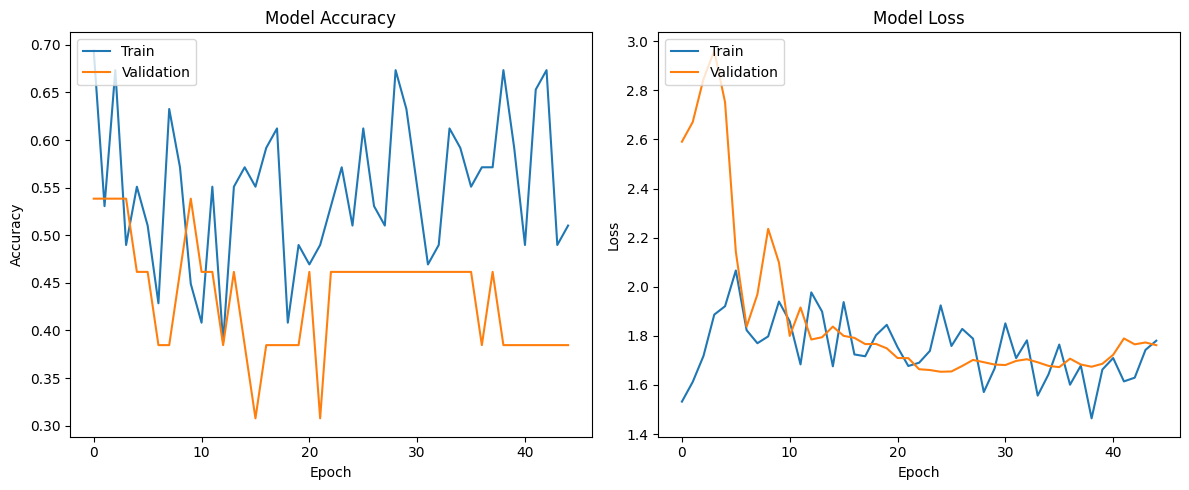

In [12]:
loss, accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Plot training history
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

# Get predictions from the model
y_pred_proba = model.predict(X_test_scaled)

# Convert probabilities to binary predictions using a threshold (e.g., 0.5)
y_pred = (y_pred_proba > 0.5).astype(int)

# Print the predicted probabilities and binary predictions
print("Predicted Probabilities:")
print(y_pred_proba)
print("\nBinary Predictions:")
print(y_pred.flatten())
print("\nTrue Labels (y_test):")
print(y_test)

# Calculate classification metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix)


In [13]:
print (model.predict(X_test_scaled), y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 259ms/step
[[0.377]
 [0.637]
 [0.373]
 [0.37 ]
 [0.39 ]
 [0.368]
 [0.418]
 [0.417]
 [0.419]
 [0.378]
 [0.437]
 [0.542]
 [0.376]
 [0.37 ]
 [0.738]
 [0.394]] [1 1 0 0 1 0 1 0 1 1 0 1 1 0 1 0]


In [14]:
test='/content/drive/MyDrive/Science_Fair_Data_2025-2026/TestSample.csv'
testdf=pd.read_csv(test)
testdf

,Substance,Laser_Intenstity,194.1151,196.1586,198.2017,200.2442,202.2863,204.3278,206.3688,208.4094,...,3357.1519,3358.3602,3359.5684,3360.7764,3361.9843,3363.1921,3364.3998,3365.6074,3366.8148,3368.0221
0,Sample A,0.40,118.5,118.5,118.5,118.5,118.5,118.5,118.5,118.5,...,9.5,4.0,10.8,14.4,6.1,7.3,8.5,5.7,5.7,5.7
1,Sample B,0.40,418.6,418.6,418.6,418.6,418.6,418.6,418.6,418.6,...,12.8,18.0,25.7,27.7,18.8,18.3,17.9,17.5,17.5,17.5
2,Sample C,0.40,151.0,151.0,151.0,151.0,151.0,151.0,151.0,151.0,...,-3.8,-9.6,-2.8,-1.5,-0.2,-1.4,0.3,-5.8,-5.8,-5.8
3,Sample D,0.40,384.7,384.7,384.7,384.7,384.7,384.7,384.7,384.7,...,0.6,-3.1,-6.5,-1.3,3.4,14.0,13.0,10.0,10.0,10.0
4,Sample E,0.40,114.9,114.9,114.9,114.9,114.9,114.9,114.9,114.9,...,9.4,10.9,6.9,7.3,5.8,4.7,-3.7,-0.1,-0.1,-0.1
5,Sample F,0.40,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,...,6.5,5.9,-1.1,-7.2,-6.9,1.2,0.6,-5.5,-5.5,-5.5
6,Noopur 20_ Laser Gold side down angled,0.20,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,-10.1,-8.0,-1.9,-4.2,-6.5,-3.5,-4.3,-1.3,-1.3,-1.3
7,Noopur 20_ Laser Gold Side down,0.20,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,...,5.1,7.4,4.0,1.0,-0.7,-2.7,-5.5,-4.2,-4.2,-4.2
8,Noopur 20_ Laser Gold Side up,0.20,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,...,0.6,-2.4,2.4,-6.1,-4.3,-7.7,-2.9,0.4,0.4,0.4
9,Noopur 30_ Laser Gold side up 2,0.30,12.2,12.2,12.2,12.2,12.2,12.2,12.2,12.2,...,2.1,3.7,8.6,8.2,-0.5,4.8,7.2,6.2,6.2,6.2


In [15]:
sampletestdf=testdf.drop('Substance', axis= 1)
sampletestdf

,Laser_Intenstity,194.1151,196.1586,198.2017,200.2442,202.2863,204.3278,206.3688,208.4094,210.4494,...,3357.1519,3358.3602,3359.5684,3360.7764,3361.9843,3363.1921,3364.3998,3365.6074,3366.8148,3368.0221
0,0.40,118.5,118.5,118.5,118.5,118.5,118.5,118.5,118.5,118.5,...,9.5,4.0,10.8,14.4,6.1,7.3,8.5,5.7,5.7,5.7
1,0.40,418.6,418.6,418.6,418.6,418.6,418.6,418.6,418.6,418.6,...,12.8,18.0,25.7,27.7,18.8,18.3,17.9,17.5,17.5,17.5
2,0.40,151.0,151.0,151.0,151.0,151.0,151.0,151.0,151.0,151.0,...,-3.8,-9.6,-2.8,-1.5,-0.2,-1.4,0.3,-5.8,-5.8,-5.8
3,0.40,384.7,384.7,384.7,384.7,384.7,384.7,384.7,384.7,384.7,...,0.6,-3.1,-6.5,-1.3,3.4,14.0,13.0,10.0,10.0,10.0
4,0.40,114.9,114.9,114.9,114.9,114.9,114.9,114.9,114.9,114.9,...,9.4,10.9,6.9,7.3,5.8,4.7,-3.7,-0.1,-0.1,-0.1
5,0.40,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,2069.0,...,6.5,5.9,-1.1,-7.2,-6.9,1.2,0.6,-5.5,-5.5,-5.5
6,0.20,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,-10.1,-8.0,-1.9,-4.2,-6.5,-3.5,-4.3,-1.3,-1.3,-1.3
7,0.20,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,-1.8,...,5.1,7.4,4.0,1.0,-0.7,-2.7,-5.5,-4.2,-4.2,-4.2
8,0.20,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,...,0.6,-2.4,2.4,-6.1,-4.3,-7.7,-2.9,0.4,0.4,0.4
9,0.30,12.2,12.2,12.2,12.2,12.2,12.2,12.2,12.2,12.2,...,2.1,3.7,8.6,8.2,-0.5,4.8,7.2,6.2,6.2,6.2


In [16]:
# Standardizing data
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(sampletestdf)
sampletest = sc.transform(sampletestdf)

In [17]:
print (testdf['Substance'], model.predict(sampletest) )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step
0                                        Sample A
1                                        Sample B
2                                        Sample C
3                                        Sample D
4                                        Sample E
5                                        Sample F
6          Noopur 20_ Laser Gold side down angled
7                 Noopur 20_ Laser Gold Side down
8                   Noopur 20_ Laser Gold Side up
9                 Noopur 30_ Laser Gold side up 2
10    Noopur 30_ Laser Gold side up new substrate
11                  Noopur 30_ Laser Gold side up
12    Noopur 35_ Laser Gold side up new substrate
13    Noopur 40_ Laser Gold side up new substrate
14    Noopur 45_ Laser Gold side up new substrate
15                  Noopur 45_ Laser no substrate
16                     Uma 40_ Laser No substrate
17                   Uma 40_ Laser Gold Substrate
Name: Substance, dtype: object [[0.394]
 [0.425]
 [0.365]
 [0

In [18]:
model.save('my_model.keras')
print("Model saved successfully!")

Model saved successfully!
